### Import libraries and load all categories

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

large_cap = pd.read_csv("Large_cap/analysis/large_cap_fund_results.csv")
mid_cap = pd.read_csv("Mid_cap/analysis/mid_cap_fund_results.csv")
small_cap = pd.read_csv("Small_cap/analysis/small_cap_fund_results.csv")

large_cap["Category"] = "Large Cap"
mid_cap["Category"] = "Mid Cap"
small_cap["Category"] = "Small Cap"

all_funds = pd.concat([large_cap, mid_cap, small_cap], ignore_index=True)

display(all_funds.head())
print("Total funds:", len(all_funds))
print(all_funds.groupby("Category")["Fund"].count())


,Fund,Start Date,End Date,Observations,Start NAV,End NAV,CAGR,Volatility,Maximum Drawdown,Sharpe Ratio,Category
0,Nippon India Large Cap,2022-01-03,2025-12-31,985,54.3991,105.3421,0.180049,0.136721,-0.153680,0.880623,Large Cap
1,ICICI Prudential Large Cap,2022-01-03,2025-12-31,985,71.0800,127.1700,0.156883,0.123998,-0.153933,0.793930,Large Cap
2,HDFC Large Cap,2022-01-03,2025-12-31,985,732.7530,1279.9530,0.149963,0.131588,-0.163646,0.708972,Large Cap
3,DSP Large Cap,2022-01-03,2025-12-31,985,312.6130,534.9380,0.144048,0.124441,-0.176848,0.699834,Large Cap
4,Bandhan Large Cap,2022-01-03,2025-12-31,991,56.4500,92.7700,0.132523,0.135343,-0.194181,0.571672,Large Cap


Total funds: 15
Category
Large Cap    5
Mid Cap      5
Small Cap    5
Name: Fund, dtype: int64


### Calculate average metrics for each category


In [35]:
metrics = ["CAGR", "Volatility", "Maximum Drawdown", "Sharpe Ratio"]
category_summary = all_funds.groupby("Category")[metrics].mean()

display(category_summary.round(4))
os.makedirs("Category_Comparison", exist_ok=True)
category_summary.to_csv("Category_Comparison/category_summary.csv")


,CAGR,Volatility,Maximum Drawdown,Sharpe Ratio
Category,,,,
Large Cap,0.1527,0.1304,-0.1685,0.7310
Mid Cap,0.1687,0.1500,-0.2010,0.7422
Small Cap,0.1494,0.1459,-0.2267,0.6451


### Plot category comparison charts

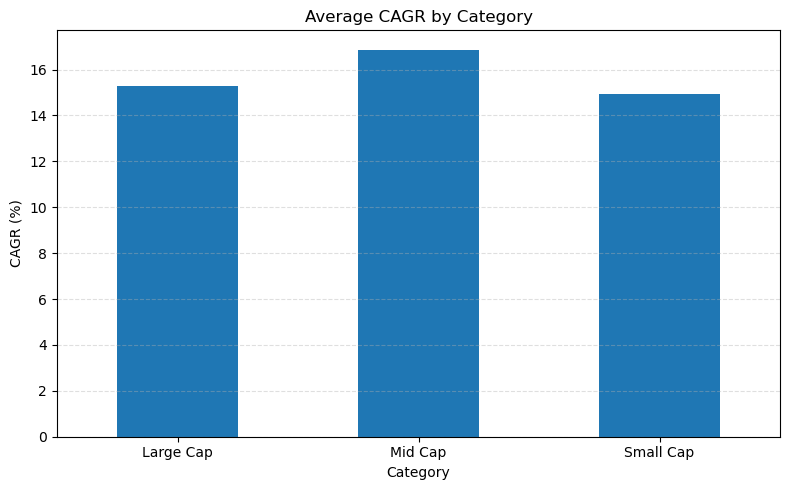

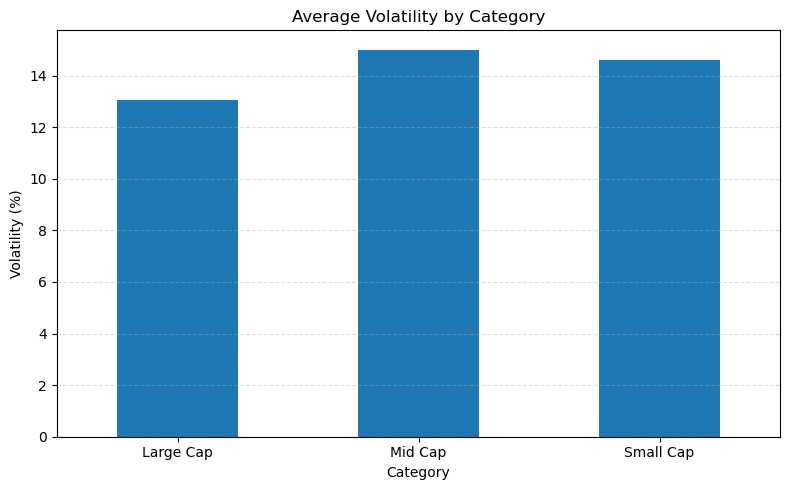

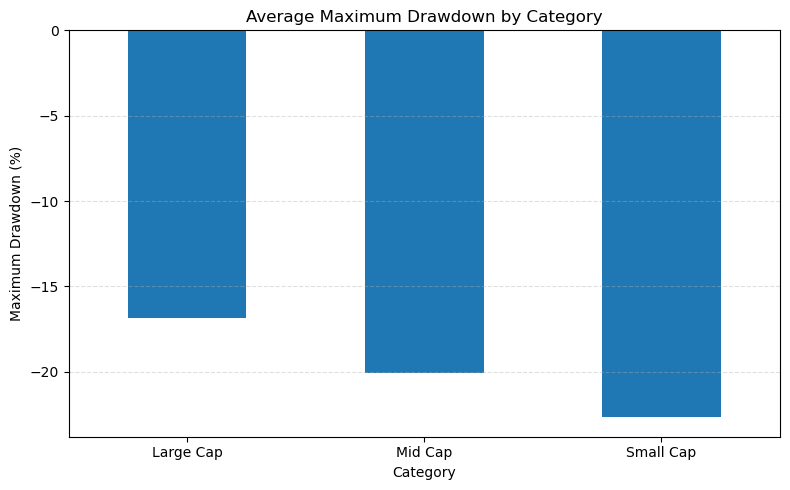

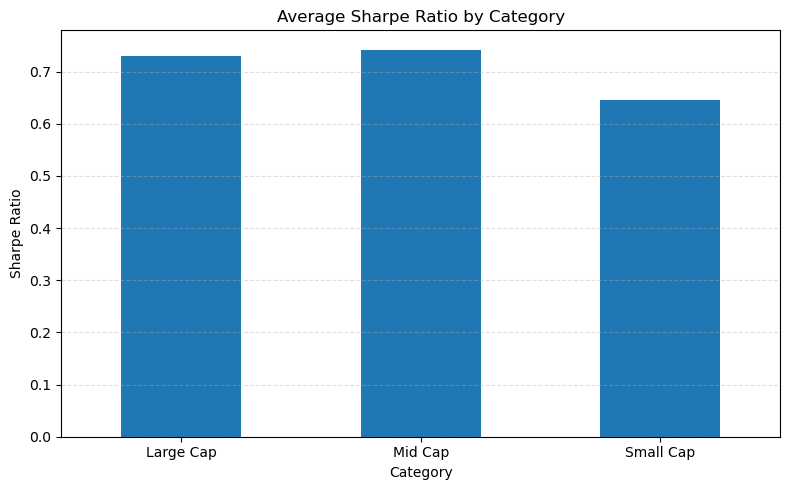

In [36]:
os.makedirs("Category_Comparison/charts", exist_ok=True)

chart_settings = {
    "CAGR": {"title": "Average CAGR by Category", "ylabel": "CAGR (%)", "multiplier": 100},
    "Volatility": {"title": "Average Volatility by Category", "ylabel": "Volatility (%)", "multiplier": 100},
    "Maximum Drawdown": {"title": "Average Maximum Drawdown by Category", "ylabel": "Maximum Drawdown (%)", "multiplier": 100},
    "Sharpe Ratio": {"title": "Average Sharpe Ratio by Category", "ylabel": "Sharpe Ratio", "multiplier": 1}
}

for metric, settings in chart_settings.items():
    values = category_summary[metric] * settings["multiplier"]
    ax = values.plot(kind="bar", figsize=(8, 5), title=settings["title"], rot=0)
    ax.set_ylabel(settings["ylabel"])
    ax.set_xlabel("Category")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(f"Category_Comparison/charts/{metric.lower().replace(' ', '_')}.png", dpi=300, bbox_inches="tight")
    plt.show()


### Create a risk-return scatter plot

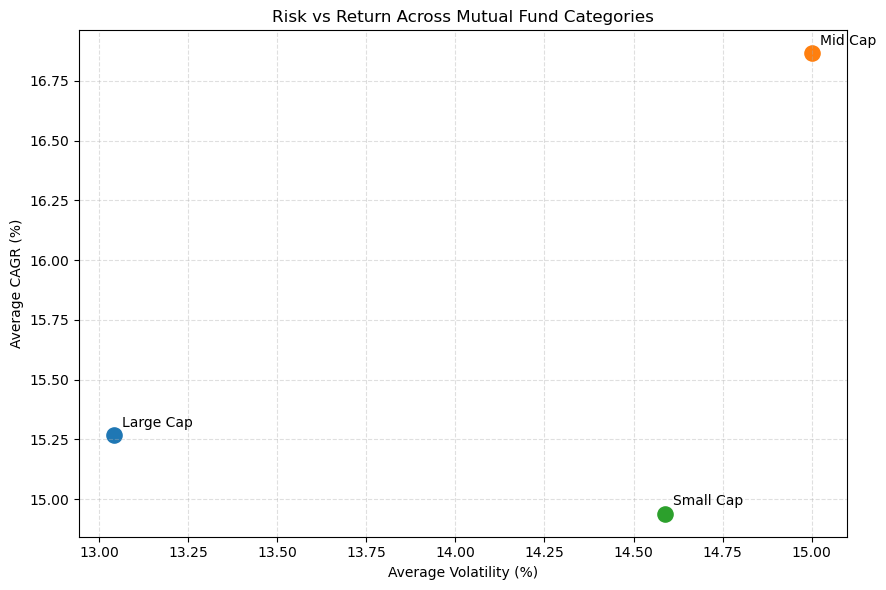

In [37]:
plt.figure(figsize=(9, 6))
for category, row in category_summary.iterrows():
    plt.scatter(row["Volatility"] * 100, row["CAGR"] * 100, s=120)
    plt.annotate(category, (row["Volatility"] * 100, row["CAGR"] * 100), xytext=(6, 6), textcoords="offset points")
plt.xlabel("Average Volatility (%)")
plt.ylabel("Average CAGR (%)")
plt.title("Risk vs Return Across Mutual Fund Categories")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Category_Comparison/charts/category_risk_return.png", dpi=300, bbox_inches="tight")
plt.show()


### Compare equal-weighted category portfolios on common NAV dates


In [38]:
# Load each fund's 2022–2025 NAV series from its per-fund analysis CSV.
nav_files = {
    "Nippon India Large Cap": "Large_cap/analysis/nippon_large_cap_analysis.csv",
    "ICICI Prudential Large Cap": "Large_cap/analysis/icici_large_cap_analysis.csv",
    "HDFC Large Cap": "Large_cap/analysis/hdfc_large_cap_analysis.csv",
    "DSP Large Cap": "Large_cap/analysis/dsp_large_cap_analysis.csv",
    "Bandhan Large Cap": "Large_cap/analysis/bandhan_large_cap_analysis.csv",
    "Aditya Birla Sun Life Midcap Fund": "Mid_cap/analysis/aditya_birla_sun_life_mid_cap_fund_analysis.csv",
    "Axis Midcap Fund": "Mid_cap/analysis/axis_mid_cap_fund_analysis.csv",
    "DSP Midcap Fund": "Mid_cap/analysis/dsp_mid_cap_fund_analysis.csv",
    "HDFC Mid Cap Fund": "Mid_cap/analysis/hdfc_mid_cap_fund_analysis.csv",
    "Mahindra Manulife Mid Cap Fund": "Mid_cap/analysis/mahindra_manulife_mid_cap_fund_analysis.csv",
    "Nippon India Small Cap": "Small_cap/analysis/nippon_small_cap_analysis.csv",
    "SBI Small Cap": "Small_cap/analysis/sbi_small_cap_analysis.csv",
    "HDFC Small Cap": "Small_cap/analysis/hdfc_small_cap_analysis.csv",
    "Axis Small Cap": "Small_cap/analysis/axis_small_cap_analysis.csv",
    "Kotak Small Cap": "Small_cap/analysis/kotak_small_cap_analysis.csv"
}

category_funds = {
    "Large Cap": large_cap["Fund"].tolist(),
    "Mid Cap": mid_cap["Fund"].tolist(),
    "Small Cap": small_cap["Fund"].tolist()
}

# Align NAV levels first, then calculate returns. This ensures every fund's
# return on a given date covers the same interval despite a few missing NAV days.
nav_series = {}
for fund_name, file_path in nav_files.items():
    df = pd.read_csv(file_path, usecols=["Date", "NAV"])
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["NAV"] = pd.to_numeric(df["NAV"], errors="coerce")
    df = df.dropna(subset=["Date", "NAV"]).sort_values("Date").drop_duplicates("Date")
    nav_series[fund_name] = df.set_index("Date")["NAV"]

common_nav = pd.concat(nav_series, axis=1, join="inner").dropna(how="any")
if common_nav.empty or len(common_nav) < 2:
    raise ValueError("Not enough NAV dates are shared by all 15 funds.")

common_returns = common_nav.pct_change().dropna(how="any")
category_portfolio_returns = {
    category: common_returns[fund_names].mean(axis=1)
    for category, fund_names in category_funds.items()
}
portfolio_returns = pd.DataFrame(category_portfolio_returns)

print("Common NAV period:", common_nav.index.min().date(), "to", common_nav.index.max().date())
print("Common NAV observations:", len(common_nav))
print("Comparable return observations:", len(portfolio_returns))
display(portfolio_returns.head())


Common NAV period: 2022-01-03 to 2025-12-31
Common NAV observations: 980
Comparable return observations: 979


,Large Cap,Mid Cap,Small Cap
Date,,,
2022-01-04,0.007730,0.004297,0.002672
2022-01-05,0.004633,0.001455,-0.000978
2022-01-06,-0.006923,-0.002198,-0.001000
2022-01-07,0.003388,0.004726,0.003056
2022-01-10,0.010445,0.006700,0.009622


### Calculate portfolio-level metrics

In [39]:
RISK_FREE_RATE = 0.06
TRADING_DAYS = 252
daily_rf = (1 + RISK_FREE_RATE) ** (1 / TRADING_DAYS) - 1
portfolio_results = []

# Use the actual elapsed calendar period for CAGR, consistent with fund-level results.
years = (common_nav.index[-1] - common_nav.index[0]).days / 365.25

for category in portfolio_returns.columns:
    returns = portfolio_returns[category].dropna()
    wealth = (1 + returns).cumprod()
    daily_std = returns.std()
    sharpe = np.nan if pd.isna(daily_std) or daily_std == 0 else ((returns - daily_rf).mean() / daily_std) * np.sqrt(TRADING_DAYS)
    drawdown = wealth / wealth.cummax() - 1

    portfolio_results.append({
        "Category": category,
        "Start Date": common_nav.index[0],
        "End Date": common_nav.index[-1],
        "Observations": len(returns),
        "CAGR": wealth.iloc[-1] ** (1 / years) - 1,
        "Volatility": daily_std * np.sqrt(TRADING_DAYS),
        "Maximum Drawdown": drawdown.min(),
        "Sharpe Ratio": sharpe
    })

portfolio_summary = pd.DataFrame(portfolio_results)
display(portfolio_summary.round(4))
portfolio_summary.to_csv("Category_Comparison/equal_weighted_portfolio_results.csv", index=False)


,Category,Start Date,End Date,Observations,CAGR,Volatility,Maximum Drawdown,Sharpe Ratio
0,Large Cap,2022-01-03,2025-12-31,979,0.1529,0.1285,-0.1556,0.7489
1,Mid Cap,2022-01-03,2025-12-31,979,0.1687,0.1474,-0.1996,0.7658
2,Small Cap,2022-01-03,2025-12-31,979,0.1499,0.1418,-0.2212,0.6726


### Graphs for equal-weighted portfolio summary


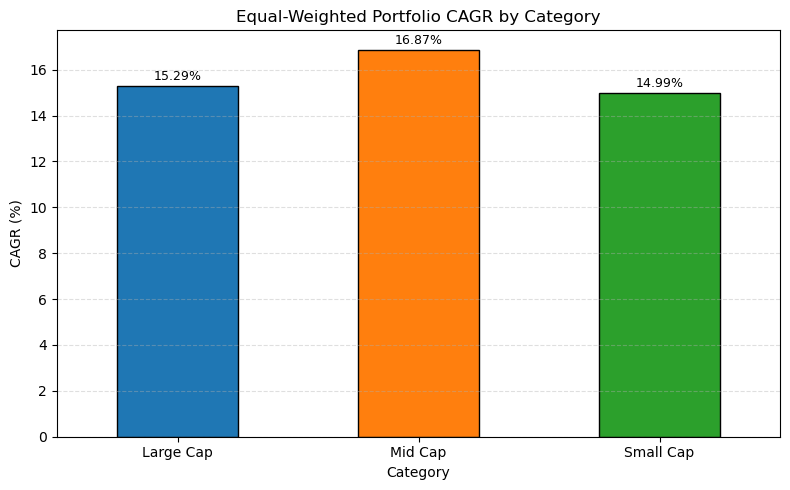

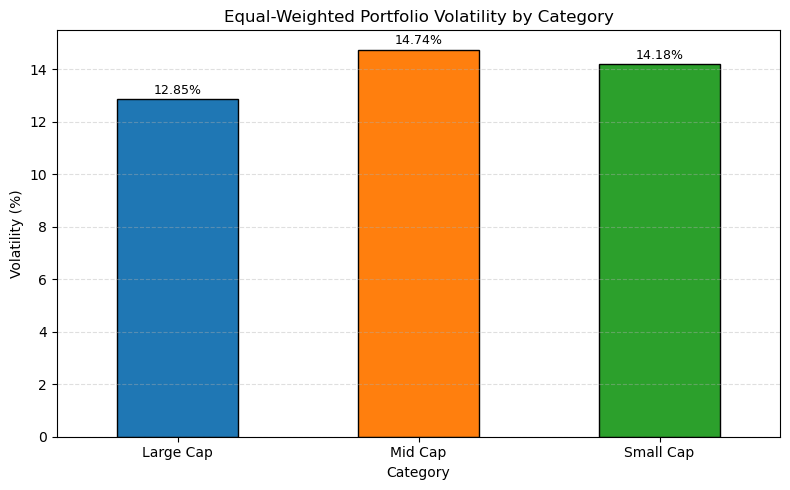

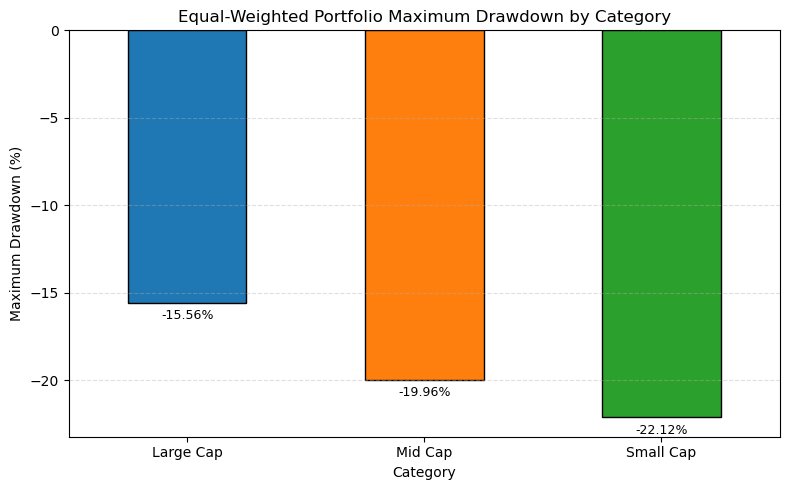

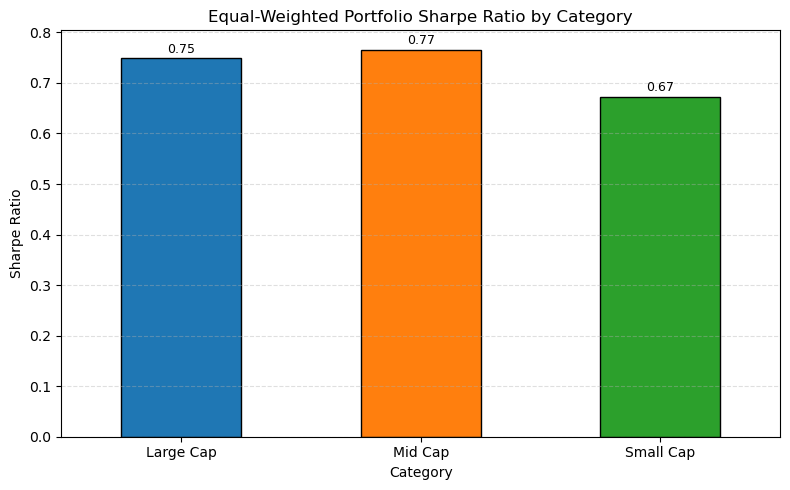

In [40]:
portfolio_chart_settings = {
    "CAGR": {"title": "Equal-Weighted Portfolio CAGR by Category", "ylabel": "CAGR (%)", "multiplier": 100},
    "Volatility": {"title": "Equal-Weighted Portfolio Volatility by Category", "ylabel": "Volatility (%)", "multiplier": 100},
    "Maximum Drawdown": {"title": "Equal-Weighted Portfolio Maximum Drawdown by Category", "ylabel": "Maximum Drawdown (%)", "multiplier": 100},
    "Sharpe Ratio": {"title": "Equal-Weighted Portfolio Sharpe Ratio by Category", "ylabel": "Sharpe Ratio", "multiplier": 1}
}

category_colors = {"Large Cap": "#1f77b4", "Mid Cap": "#ff7f0e", "Small Cap": "#2ca02c"}

for metric, settings in portfolio_chart_settings.items():
    values = portfolio_summary.set_index("Category")[metric] * settings["multiplier"]
    colors = [category_colors.get(category, "#7f7f7f") for category in values.index]

    ax = values.plot(kind="bar", figsize=(8, 5), color=colors, edgecolor="black", title=settings["title"], rot=0)
    ax.set_ylabel(settings["ylabel"])
    ax.set_xlabel("Category")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    for bar in ax.patches:
        height = bar.get_height()
        label = f"{height:.2f}%" if settings["multiplier"] == 100 else f"{height:.2f}"
        offset = 0.4 if height >= 0 else -0.8
        ax.annotate(label, (bar.get_x() + bar.get_width() / 2, height), xytext=(0, 4 if height >= 0 else -12), textcoords="offset points", ha="center", fontsize=9)

    plt.tight_layout()
    plt.savefig(
        f"Category_Comparison/charts/equal_weighted_portfolio_{metric.lower().replace(' ', '_')}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


### Portfolio risk-return comparison


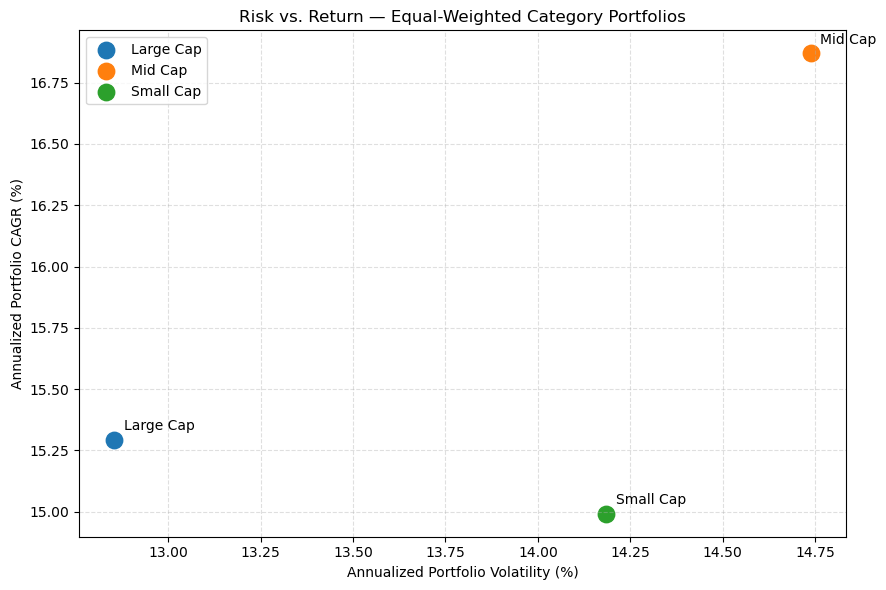

In [41]:
portfolio_plot = portfolio_summary.set_index("Category")
plt.figure(figsize=(9, 6))

for category, row in portfolio_plot.iterrows():
    plt.scatter(row["Volatility"] * 100, row["CAGR"] * 100, s=140, color=category_colors.get(category, "#7f7f7f"), label=category)
    plt.annotate(category, (row["Volatility"] * 100, row["CAGR"] * 100), xytext=(7, 7), textcoords="offset points")

plt.xlabel("Annualized Portfolio Volatility (%)")
plt.ylabel("Annualized Portfolio CAGR (%)")
plt.title("Risk vs. Return — Equal-Weighted Category Portfolios")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("Category_Comparison/charts/equal_weighted_portfolio_risk_return.png", dpi=300, bbox_inches="tight")
plt.show()
